# Hybrid ticker linking: FLANG-RoBERTa top-k + Jev rerank

End-to-end Kaggle notebook for **Financial News ticker linking**.

**Stage 1 — retriever.** Fine-tune **FLANG-RoBERTa** as a 49-label multi-label classifier. For each article it scores every ticker and keeps the **top-k** candidates.

**Stage 2 — reranker.** Call OpenCode Zen **Jev 1.13 Free** only on those k tickers (`noul` yes/no questions). Tickers outside the shortlist are treated as negatives. That cuts Jev questions from 49 per article down to `TOP_K`.

**Before running**
- Attach the benchmark dataset as a Kaggle **Input** (`financial_news_ticker_linking.csv`).
- Enable **Internet**.
- Add a Kaggle Secret named `OPENCODE_API_KEY` before the Jev cells.
- Start with the row limits below. Set limits to `None` only after a capped run works.

FLANG-RoBERTa is trained on the time-based train split. Jev is used for inference only on validation/test shortlists. The hybrid ceiling is retriever recall@k: gold tickers dropped in stage 1 cannot be recovered by Jev.


## 1. Dependencies

Run this cell first. Kaggle usually already has a CUDA PyTorch build; leave that version installed. Restart the session if a newly installed package was already imported.


In [1]:
%pip install -q "transformers<5" sentencepiece requests pandas numpy scikit-learn matplotlib seaborn tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 99.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 87.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## 2. Configuration


In [2]:
from pathlib import Path
import ast
import hashlib
import json
import os
import random
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
from sklearn.metrics import (
    average_precision_score, f1_score, hamming_loss, precision_score, recall_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/hybrid_flang_jev_ticker")
CACHE_DIR = OUTPUT_DIR / "cache"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

FLANG_CHECKPOINT = "SALT-NLP/FLANG-Roberta"
TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 20
ENCODER_LR = 2e-5
HEAD_LR = 5e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
DROPOUT = 0.20
HEAD_HIDDEN_SIZES = (256,)
PATIENCE = 5
MAX_TEXT_CHARS = 2000
TRAIN_ROW_LIMIT = 10000
EVAL_ROW_LIMIT = 3000

TOP_K = 10
JEV_VALIDATION_LIMIT = 30
JEV_TEST_LIMIT = 50
BASE_URL = "https://opencode.ai/zen/v1"
JEV_MODEL_NAME = "jev-1.13-free"
REQUEST_TIMEOUT_SECONDS = 90
MAX_RETRIES = 8
MIN_REQUEST_INTERVAL_SECONDS = 2.5
ARTICLE_CHAR_LIMIT = 12000

TICKERS = [
    "AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA", "BRK.B", "JPM", "V",
    "JNJ", "WMT", "PG", "MA", "HD", "XOM", "CVX", "LLY", "ABBV", "MRK", "BAC",
    "KO", "PEP", "COST", "AVGO", "ORCL", "ADBE", "CRM", "NFLX", "AMD", "INTC",
    "CSCO", "QCOM", "TXN", "IBM", "DIS", "NKE", "MCD", "T", "PFE", "UNH", "CAT",
    "GE", "BA", "GS", "C", "WFC", "PYPL", "UBER",
]
TICKER_ENTITY_NAMES = {
    "AAPL": "Apple", "MSFT": "Microsoft", "GOOGL": "Alphabet / Google", "AMZN": "Amazon",
    "NVDA": "NVIDIA", "META": "Meta / Facebook", "TSLA": "Tesla", "BRK.B": "Berkshire Hathaway",
    "JPM": "JPMorgan Chase", "V": "Visa", "JNJ": "Johnson & Johnson", "WMT": "Walmart",
    "PG": "Procter & Gamble", "MA": "Mastercard", "HD": "Home Depot", "XOM": "ExxonMobil",
    "CVX": "Chevron", "LLY": "Eli Lilly", "ABBV": "AbbVie", "MRK": "Merck",
    "BAC": "Bank of America", "KO": "Coca-Cola", "PEP": "PepsiCo", "COST": "Costco",
    "AVGO": "Broadcom", "ORCL": "Oracle", "ADBE": "Adobe", "CRM": "Salesforce",
    "NFLX": "Netflix", "AMD": "Advanced Micro Devices", "INTC": "Intel", "CSCO": "Cisco",
    "QCOM": "Qualcomm", "TXN": "Texas Instruments", "IBM": "IBM", "DIS": "Disney",
    "NKE": "Nike", "MCD": "McDonald's", "T": "AT&T", "PFE": "Pfizer",
    "UNH": "UnitedHealth", "CAT": "Caterpillar", "GE": "GE", "BA": "Boeing",
    "GS": "Goldman Sachs", "C": "Citigroup", "WFC": "Wells Fargo", "PYPL": "PayPal",
    "UBER": "Uber",
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
matches = list(INPUT_ROOT.rglob("financial_news_ticker_linking.csv")) if INPUT_ROOT.exists() else []
if not matches:
    raise FileNotFoundError(
        "Could not find financial_news_ticker_linking.csv under /kaggle/input. "
        "Attach the benchmark dataset as a Kaggle Input."
    )
DATA_PATH = matches[0]
print("Data:", DATA_PATH)
print("Device:", DEVICE)
print("FLANG checkpoint:", FLANG_CHECKPOINT)
print("Top-k:", TOP_K, "| Jev val/test limits:", JEV_VALIDATION_LIMIT, JEV_TEST_LIMIT)
print("Jev questions per article:", TOP_K, "instead of", len(TICKERS))


Data: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/financial_news_ticker_linking.csv
Device: cuda
FLANG checkpoint: SALT-NLP/FLANG-Roberta
Top-k: 10 | Jev val/test limits: 30 50
Jev questions per article: 10 instead of 49


## 3. OpenCode Zen client and resumable cache

The secret is read here but Jev is not called until after FLANG-RoBERTa is trained and has produced shortlists.


In [3]:
API_KEY = "oc_sk_470d2f29b21e_n7_jXjOhhZvZVMALlnoGVCj5OxH3qRMu"
SESSION = requests.Session()
if API_KEY:
    SESSION.headers.update({"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"})
else:
    print("OPENCODE_API_KEY is not set yet. FLANG training can still run; Jev cells will fail until the secret is added.")

def require_jev_key():
    if not API_KEY:
        raise RuntimeError("Set a Kaggle Secret named OPENCODE_API_KEY before running the Jev rerank cells.")

def stable_id(task, row_id):
    return f"{task}__{hashlib.sha1(str(row_id).encode('utf-8')).hexdigest()}"

def cache_path(task):
    return CACHE_DIR / f"{task}.jsonl"

def read_cache(task):
    path = cache_path(task)
    results = {}
    if path.exists():
        with path.open(encoding="utf-8") as f:
            for line in f:
                try:
                    item = json.loads(line)
                    if item.get("ok"):
                        results[item["id"]] = item["response"]
                except (json.JSONDecodeError, KeyError):
                    pass
    return results

def append_cache(task, item):
    with cache_path(task).open("a", encoding="utf-8") as f:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

def retry_delay(response, attempt):
    retry_after = response.headers.get("Retry-After") if response is not None else None
    if retry_after:
        try:
            return max(1.0, min(float(retry_after), 300.0))
        except ValueError:
            try:
                from datetime import datetime, timezone
                from email.utils import parsedate_to_datetime
                retry_at = parsedate_to_datetime(retry_after)
                return max(1.0, min((retry_at - datetime.now(timezone.utc)).total_seconds(), 300.0))
            except Exception:
                pass
    return min(10.0 * (2 ** attempt), 300.0)

def ask_jev(state, questions):
    require_jev_key()
    body = {"model": JEV_MODEL_NAME, "state": state, "questions": questions}
    for attempt in range(MAX_RETRIES):
        try:
            response = SESSION.post(f"{BASE_URL}/systemone", json=body, timeout=REQUEST_TIMEOUT_SECONDS)
        except requests.RequestException as exc:
            if attempt + 1 >= MAX_RETRIES:
                raise
            delay = min(2 ** attempt, 60)
            print(f"Temporary network error; retrying in {delay}s ({attempt + 1}/{MAX_RETRIES}).")
            time.sleep(delay)
            continue
        if response.status_code == 429 or response.status_code >= 500:
            if attempt + 1 < MAX_RETRIES:
                delay = retry_delay(response, attempt)
                print(f"OpenCode Zen returned {response.status_code}; retrying in {delay:.0f}s ({attempt + 1}/{MAX_RETRIES}).")
                time.sleep(delay)
                continue
        if response.status_code >= 400:
            raise requests.HTTPError(
                f"{response.status_code} {response.reason}: {response.text[:2000]}",
                response=response,
            )
        return response.json()
    raise RuntimeError("Jev request failed after retries")


## 4. Dataset, temporal splits, and model


In [4]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def parse_tickers(value):
    if pd.isna(value) or not str(value).strip():
        return []
    try:
        items = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        try:
            items = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return []
    if isinstance(items, str):
        items = [items]
    if not isinstance(items, (list, tuple, set)):
        return []
    parsed = {str(item).strip().upper().lstrip("$") for item in items if str(item).strip()}
    return sorted(parsed & set(TICKERS))

def normalize_title(value):
    value = str(value or "").lower()
    return re.sub(r"[^a-z0-9]+", " ", value).strip()

def prepare_dataframe():
    required = ["text", "title", "description", "date_publish", "url", "mentioned_companies"]
    frame = pd.read_csv(DATA_PATH, usecols=required, low_memory=False, encoding="utf-8-sig")
    frame["gold_tickers"] = frame["mentioned_companies"].apply(parse_tickers)
    frame = frame[frame["gold_tickers"].map(len) > 0].copy()
    frame["date"] = pd.to_datetime(frame["date_publish"], errors="coerce", utc=True)
    frame["url"] = frame["url"].fillna("").astype(str).str.strip()
    frame["title"] = frame["title"].fillna("").astype(str)
    frame["description"] = frame["description"].fillna("").astype(str)
    frame["text"] = frame["text"].fillna("").astype(str)
    frame = frame.sort_values("date", kind="stable", na_position="first")
    has_url = frame["url"].ne("")
    unique_url_rows = frame.loc[has_url].drop_duplicates("url", keep="first")
    no_url_rows = frame.loc[~has_url]
    frame = pd.concat([unique_url_rows, no_url_rows]).sort_values("date", kind="stable", na_position="first")
    frame["title_key"] = frame["title"].map(normalize_title)
    row_ids = np.arange(len(frame))
    frame["group_key"] = [f"title:{key}" if key else f"row:{i}" for key, i in zip(frame["title_key"], row_ids)]
    frame["model_text"] = (
        "Title: " + frame["title"] + "\nSummary: " + frame["description"] + "\nArticle: " + frame["text"]
    ).str.slice(0, MAX_TEXT_CHARS)
    frame["target_vector"] = frame["gold_tickers"].apply(
        lambda tickers: np.array([1.0 if t in tickers else 0.0 for t in TICKERS], dtype=np.float32)
    )
    return frame.reset_index(drop=True)

def make_temporal_splits(frame):
    group_dates = frame.groupby("group_key", sort=False)["date"].max().dropna().sort_values(kind="stable")
    if len(group_dates) < 3:
        raise ValueError("Too few dated headline groups for temporal train/validation/test splitting.")
    train_cut = group_dates.iloc[min(int(len(group_dates) * TRAIN_FRACTION), len(group_dates) - 2)]
    val_cut_index = min(int(len(group_dates) * (TRAIN_FRACTION + VALIDATION_FRACTION)), len(group_dates) - 1)
    val_cut = group_dates.iloc[val_cut_index]
    max_date_by_group = frame.groupby("group_key", sort=False)["date"].max()
    group_split = {}
    for group, group_date in max_date_by_group.items():
        if pd.isna(group_date) or group_date <= train_cut:
            group_split[group] = "train"
        elif group_date <= val_cut:
            group_split[group] = "validation"
        else:
            group_split[group] = "test"
    frame = frame.copy()
    frame["split"] = frame["group_key"].map(group_split)
    return {name: frame[frame["split"] == name].reset_index(drop=True) for name in ["train", "validation", "test"]}

def cap_frame(part, limit, seed=SEED):
    if limit is not None and len(part) > limit:
        return part.sample(n=limit, random_state=seed).sort_index().reset_index(drop=True)
    return part.reset_index(drop=True)

frame = prepare_dataframe()
splits = make_temporal_splits(frame)
splits["train"] = cap_frame(splits["train"], TRAIN_ROW_LIMIT)
splits["validation"] = cap_frame(splits["validation"], EVAL_ROW_LIMIT)
splits["test"] = cap_frame(splits["test"], EVAL_ROW_LIMIT)
for name, part in splits.items():
    part["_row_id"] = [f"{name}:{i}" for i in range(len(part))]
    splits[name] = part
if any(part.empty for part in splits.values()):
    raise ValueError("A temporal split is empty; inspect publication dates and split fractions.")

print("Rows by split:", {name: len(part) for name, part in splits.items()})
print("Publication-date ranges:", {name: (part["date"].min(), part["date"].max()) for name, part in splits.items()})
print("Mean gold tickers per article:", {name: part["gold_tickers"].map(len).mean() for name, part in splits.items()})


Rows by split: {'train': 10000, 'validation': 3000, 'test': 3000}
Publication-date ranges: {'train': (Timestamp('2017-01-03 02:21:14+0000', tz='UTC'), Timestamp('2023-03-01 13:00:00+0000', tz='UTC')), 'validation': (Timestamp('2020-12-04 13:00:00+0000', tz='UTC'), Timestamp('2023-07-29 13:50:15+0000', tz='UTC')), 'test': (Timestamp('2022-01-23 15:38:23+0000', tz='UTC'), Timestamp('2023-12-30 18:15:00+0000', tz='UTC'))}
Mean gold tickers per article: {'train': np.float64(1.3384), 'validation': np.float64(1.4323333333333332), 'test': np.float64(1.4206666666666667)}


In [5]:
class MultiLabelClassificationHead(nn.Module):
    def __init__(self, hidden_size, num_labels, dropout=0.25, hidden_sizes=(256,)):
        super().__init__()
        layers, input_size = [], hidden_size
        for width in hidden_sizes:
            layers.extend([nn.Linear(input_size, width), nn.LayerNorm(width), nn.GELU(), nn.Dropout(dropout)])
            input_size = width
        layers.append(nn.Linear(input_size, num_labels))
        self.network = nn.Sequential(*layers)

    def forward(self, pooled):
        return self.network(pooled)

class FinancialTextMultiLabelClassifier(nn.Module):
    def __init__(self, checkpoint, num_labels, dropout=DROPOUT, hidden_sizes=HEAD_HIDDEN_SIZES):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(checkpoint)
        config = self.encoder.config
        hidden_size = getattr(config, "hidden_size", None) or getattr(config, "dim", None) or getattr(config, "d_model", None)
        if hidden_size is None:
            raise ValueError(f"Could not infer hidden size for {checkpoint}")
        self.head = MultiLabelClassificationHead(int(hidden_size), num_labels, dropout, hidden_sizes)

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
        if token_type_ids is not None:
            inputs["token_type_ids"] = token_type_ids
        output = self.encoder(**inputs)
        pooled = getattr(output, "pooler_output", None)
        if pooled is None:
            pooled = output.last_hidden_state[:, 0]
        return self.head(pooled)

class NewsTickerDataset(Dataset):
    def __init__(self, part, tokenizer, max_length, split_name="data"):
        texts = part["model_text"].astype(str).tolist()
        self.targets = np.stack(part["target_vector"].to_numpy()).astype(np.float32)
        self.examples = []
        chunk_size = 512
        for start in tqdm(range(0, len(texts), chunk_size), desc=f"Tokenizing {split_name}", leave=True):
            encoded = tokenizer(texts[start:start + chunk_size], truncation=True, max_length=max_length, padding=False)
            keys = list(encoded.keys())
            self.examples.extend([{key: encoded[key][i] for key in keys} for i in range(len(encoded["input_ids"]))])

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        item = dict(self.examples[index])
        item["labels"] = self.targets[index]
        return item

def make_collator(tokenizer):
    def collate(items):
        labels = torch.tensor(np.stack([item.pop("labels") for item in items]), dtype=torch.float32)
        batch = tokenizer.pad(items, padding=True, return_tensors="pt")
        batch["labels"] = labels
        return batch
    return collate

def make_loader(part, tokenizer, max_length, shuffle=False, split_name="data"):
    dataset = NewsTickerDataset(part, tokenizer, max_length, split_name=split_name)
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
        pin_memory=DEVICE.type == "cuda", collate_fn=make_collator(tokenizer),
    )

def effective_max_length(model, tokenizer):
    config = model.encoder.config
    position_limit = getattr(config, "max_position_embeddings", MAX_LENGTH)
    if getattr(config, "model_type", "") in {"roberta", "bart"}:
        position_limit = position_limit - int(getattr(config, "pad_token_id", 1)) - 1
    tokenizer_limit = getattr(tokenizer, "model_max_length", MAX_LENGTH)
    if tokenizer_limit is None or tokenizer_limit > 100000:
        tokenizer_limit = MAX_LENGTH
    length = min(MAX_LENGTH, int(position_limit), int(tokenizer_limit))
    if length < 8:
        raise ValueError(f"Invalid maximum input length {length}")
    return length

@torch.no_grad()
def score_loader(model, loader):
    model.eval()
    actual, probabilities = [], []
    for batch in tqdm(loader, desc="Scoring", leave=False):
        labels = batch.pop("labels")
        batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(**batch)
        actual.append(labels.numpy())
        probabilities.append(torch.sigmoid(logits).float().cpu().numpy())
    return np.concatenate(actual), np.concatenate(probabilities)


## 5. Train FLANG-RoBERTa retriever


In [6]:
set_seed()
print(f"Loading tokenizer and encoder: {FLANG_CHECKPOINT}", flush=True)
try:
    tokenizer = AutoTokenizer.from_pretrained(FLANG_CHECKPOINT, use_fast=True)
except Exception as exc:
    print(f"Fast tokenizer unavailable ({exc}); using slow tokenizer.", flush=True)
    tokenizer = AutoTokenizer.from_pretrained(FLANG_CHECKPOINT, use_fast=False)
model = FinancialTextMultiLabelClassifier(FLANG_CHECKPOINT, len(TICKERS)).to(DEVICE)
max_length = effective_max_length(model, tokenizer)
print(f"Using max_length={max_length}", flush=True)

train_loader = make_loader(splits["train"], tokenizer, max_length, shuffle=True, split_name="train")
val_loader = make_loader(splits["validation"], tokenizer, max_length, split_name="validation")
test_loader = make_loader(splits["test"], tokenizer, max_length, split_name="test")

target_matrix = np.stack(splits["train"]["target_vector"].to_numpy())
positives = target_matrix.sum(axis=0)
negatives = len(target_matrix) - positives
pos_weight = np.sqrt(negatives / np.maximum(positives, 1.0))
pos_weight = torch.tensor(np.clip(pos_weight, 1.0, 20.0), dtype=torch.float32, device=DEVICE)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
head_params = list(model.head.parameters())
head_ids = {id(param) for param in head_params}
encoder_params = [param for param in model.parameters() if id(param) not in head_ids]
optimizer = torch.optim.AdamW(
    [{"params": encoder_params, "lr": ENCODER_LR}, {"params": head_params, "lr": HEAD_LR}],
    weight_decay=WEIGHT_DECAY,
)
total_steps = max(1, len(train_loader) * EPOCHS)
scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * WARMUP_RATIO), total_steps)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
best_val_f1, best_state, stale, history = -1.0, None, 0, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, seen = 0.0, 0
    print(f"Starting epoch {epoch}/{EPOCHS}...", flush=True)
    for batch in tqdm(train_loader, desc=f"FLANG-RoBERTa epoch {epoch}/{EPOCHS}", leave=True):
        labels = batch.pop("labels").to(DEVICE, non_blocking=True)
        batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(**batch)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        loss_sum += loss.item() * labels.size(0)
        seen += labels.size(0)
    y_val, p_val = score_loader(model, val_loader)
    val_macro_f1 = f1_score(y_val, p_val >= 0.5, average="macro", zero_division=0)
    row = {"epoch": epoch, "train_loss": loss_sum / max(seen, 1), "val_macro_f1": val_macro_f1}
    history.append(row)
    print(f"epoch {epoch}: train_loss={row['train_loss']:.4f}, val_macro_f1={val_macro_f1:.4f}")
    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        stale = 0
    else:
        stale += 1
        if stale >= PATIENCE:
            print("Early stopping: validation macro-F1 did not improve.")
            break

model.load_state_dict(best_state)
y_val, p_val = score_loader(model, val_loader)
y_test, p_test = score_loader(model, test_loader)
print("FLANG-RoBERTa scoring complete.")


Loading tokenizer and encoder: SALT-NLP/FLANG-Roberta


tokenizer_config.json:   0%|          | 0.00/311 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/761 [00:00<?, ?B/s]

...

Scoring:   0%|          | 0/188 [00:00<?, ?it/s]

epoch 20: train_loss=0.0368, val_macro_f1=0.3641


Scoring:   0%|          | 0/188 [00:00<?, ?it/s]

Scoring:   0%|          | 0/188 [00:00<?, ?it/s]

FLANG-RoBERTa scoring complete.


## 6. Retriever evaluation and top-k shortlists

Recall@k is the fraction of gold tickers that land in the FLANG-RoBERTa shortlist. It is the hybrid system's recall ceiling.


In [7]:
def multilabel_metrics(actual, predicted, probabilities=None):
    result = {
        "micro_f1": f1_score(actual, predicted, average="micro", zero_division=0),
        "macro_f1": f1_score(actual, predicted, average="macro", zero_division=0),
        "micro_precision": precision_score(actual, predicted, average="micro", zero_division=0),
        "micro_recall": recall_score(actual, predicted, average="micro", zero_division=0),
        "macro_precision": precision_score(actual, predicted, average="macro", zero_division=0),
        "macro_recall": recall_score(actual, predicted, average="macro", zero_division=0),
        "exact_match": float(np.mean(np.all(actual == predicted, axis=1))),
        "hamming_loss": hamming_loss(actual, predicted),
    }
    if probabilities is not None:
        ap_values = [
            average_precision_score(actual[:, i], probabilities[:, i])
            for i in range(actual.shape[1]) if actual[:, i].sum() > 0
        ]
        result["macro_average_precision"] = float(np.mean(ap_values)) if ap_values else float("nan")
        result["macro_ap_label_count"] = int((actual.sum(axis=0) > 0).sum())
    return result

def tune_global_threshold(actual, probabilities):
    candidates = np.arange(0.05, 0.951, 0.025)
    scored = [
        (f1_score(actual, probabilities >= threshold, average="macro", zero_division=0), threshold)
        for threshold in candidates
    ]
    return max(scored, key=lambda item: item[0])

def recall_at_k(actual, probabilities, k):
    if len(actual) == 0:
        return float("nan")
    hits, total = 0.0, 0.0
    for gold, scores in zip(actual, probabilities):
        gold_idx = np.flatnonzero(gold > 0)
        if len(gold_idx) == 0:
            continue
        top = np.argpartition(-scores, min(k, len(scores) - 1))[:k]
        hits += np.intersect1d(gold_idx, top).size
        total += gold_idx.size
    return hits / total if total else float("nan")

def exact_coverage_at_k(actual, probabilities, k):
    if len(actual) == 0:
        return float("nan")
    covered = []
    for gold, scores in zip(actual, probabilities):
        gold_idx = np.flatnonzero(gold > 0)
        top = set(np.argpartition(-scores, min(k, len(scores) - 1))[:k].tolist())
        covered.append(bool(gold_idx.size) and set(gold_idx.tolist()).issubset(top))
    return float(np.mean(covered))

def top_k_symbols(scores, k=TOP_K):
    order = np.argsort(-scores)[:k]
    return [TICKERS[i] for i in order]

flang_threshold, flang_val_macro_f1 = tune_global_threshold(y_val, p_val)
flang_test_pred = (p_test >= flang_threshold).astype(int)
flang_metrics = {
    "system": "FLANG-RoBERTa threshold",
    "n": len(y_test),
    "threshold": float(flang_threshold),
    **multilabel_metrics(y_test, flang_test_pred, p_test),
    "recall_at_k": recall_at_k(y_test, p_test, TOP_K),
    "exact_gold_in_top_k": exact_coverage_at_k(y_test, p_test, TOP_K),
}
print("Validation-selected FLANG threshold:", round(float(flang_threshold), 3), "macro F1:", flang_val_macro_f1)
print(f"Test recall@{TOP_K}:", flang_metrics["recall_at_k"])
print(f"Test articles whose full gold set is inside top-{TOP_K}:", flang_metrics["exact_gold_in_top_k"])
display(pd.DataFrame([flang_metrics]))

history_df = pd.DataFrame(history)
display(history_df)


Validation-selected FLANG threshold: 0.365 macro F1: 0.6750000000000003
Test recall@10: 0.821445330830596
Test articles whose full gold set is inside top-10: 0.783


,system,n,threshold,micro_f1,macro_f1,micro_precision,micro_recall,macro_precision,macro_recall,exact_match,hamming_loss,macro_average_precision,macro_ap_label_count,recall_at_k,exact_gold_in_top_k
0,FLANG-RoBERTa threshold,3000,0.364611,0.474193,0.349467,0.445706,0.50657,0.357907,0.365403,0.314667,0.032571,0.43462,39,0.821445,0.783


,epoch,train_loss,val_macro_f1
0,1,0.475041,0.000000
1,2,0.308875,0.166757
2,3,0.252611,0.265911
3,4,0.220180,0.287207
4,5,0.192128,0.314575
5,6,0.166635,0.350875
6,7,0.143372,0.348764
7,8,0.123774,0.325443
8,9,0.106991,0.347583
9,10,0.092551,0.351479


## 7. Jev rerank on the top-k shortlist

Each article produces **one** Jev request with `TOP_K` `noul` questions. Tickers that FLANG-RoBERTa did not shortlist receive score `0` and cannot be predicted positive.


In [8]:
def ticker_questions(symbols):
    questions = {}
    for symbol in symbols:
        company = TICKER_ENTITY_NAMES.get(symbol, symbol)
        questions[symbol] = {
            "type": "noul",
            "instructions": (
                f"Does this article refer to {company} ({symbol}) as a relevant company or security? "
                "Answer yes only when the article is about or explicitly discusses this company, "
                "not just an incidental unrelated mention."
            ),
            "criteria": {
                "true": f"The article is about or explicitly discusses {company} ({symbol}).",
                "false": f"The article is not about or does not explicitly discuss {company} ({symbol}).",
            },
        }
    return questions

def ticker_state(row):
    text = str(row.title) + "\n\n" + str(row.text)
    return {"article": text[:ARTICLE_CHAR_LIMIT]}

def attach_shortlists(part, probabilities):
    out = part.copy()
    out["flang_scores"] = [row.tolist() for row in probabilities]
    out["shortlist"] = [top_k_symbols(row, TOP_K) for row in probabilities]
    return out

def apply_limit(frame, limit):
    if limit is None or len(frame) <= limit:
        return frame.reset_index(drop=True)
    return frame.head(limit).reset_index(drop=True)

val_scored = attach_shortlists(splits["validation"], p_val)
test_scored = attach_shortlists(splits["test"], p_test)
val_jev_rows = apply_limit(val_scored, JEV_VALIDATION_LIMIT)
test_jev_rows = apply_limit(test_scored, JEV_TEST_LIMIT)
print("Jev validation/test articles:", len(val_jev_rows), len(test_jev_rows))
print("Example shortlist:", test_jev_rows.iloc[0].shortlist if len(test_jev_rows) else None)
print("Example gold:", test_jev_rows.iloc[0].gold_tickers if len(test_jev_rows) else None)

def run_jev_shortlists(task, rows):
    cached = read_cache(task)
    output = []
    pending = [r for _, r in rows.iterrows() if stable_id(task, r["_row_id"]) not in cached]
    print(f"{task}: {len(rows)} selected, {len(rows) - len(pending)} cached, {len(pending)} API calls remain")
    print(f"{task}: {len(pending) * TOP_K} noul questions if none are cached")
    for _, row in tqdm(list(rows.iterrows()), total=len(rows), desc=task):
        rid = stable_id(task, row["_row_id"])
        response = cached.get(rid)
        if response is None:
            try:
                response = ask_jev(ticker_state(row), ticker_questions(row["shortlist"]))
                append_cache(task, {"id": rid, "ok": True, "response": response, "shortlist": row["shortlist"]})
            except Exception as exc:
                append_cache(task, {"id": rid, "ok": False, "error": repr(exc), "shortlist": row["shortlist"]})
                print(f"Request failed for row {row['_row_id']}: {exc}")
                if isinstance(exc, requests.HTTPError) and exc.response is not None and exc.response.status_code == 429:
                    raise RuntimeError(
                        "Rate limit persisted after retries. Successful rows are cached; wait before rerunning this cell."
                    ) from exc
                continue
        output.append({"_row_id": row["_row_id"], "response": response, "shortlist": row["shortlist"]})
        time.sleep(MIN_REQUEST_INTERVAL_SECONDS)
    return pd.DataFrame(output)

val_jev = run_jev_shortlists("hybrid_ticker_validation", val_jev_rows)
test_jev = run_jev_shortlists("hybrid_ticker_test", test_jev_rows)


Jev validation/test articles: 30 50
Example shortlist: ['MSFT', 'AAPL', 'META', 'GOOGL', 'INTC', 'AMZN', 'NVDA', 'NFLX', 'MA', 'TSLA']
Example gold: ['AAPL', 'MSFT']
hybrid_ticker_validation: 30 selected, 0 cached, 30 API calls remain
hybrid_ticker_validation: 300 noul questions if none are cached


hybrid_ticker_validation:   0%|          | 0/30 [00:00<?, ?it/s]

hybrid_ticker_test: 50 selected, 0 cached, 50 API calls remain
hybrid_ticker_test: 500 noul questions if none are cached


hybrid_ticker_test:   0%|          | 0/50 [00:00<?, ?it/s]

## 8. Hybrid scores, threshold, and comparison


In [9]:
def hybrid_score_matrix(part, jev_pred):
    joined = part.merge(jev_pred[["_row_id", "response"]], on="_row_id", how="inner")
    gold, hybrid, retriever, shortlists, row_ids = [], [], [], [], []
    for _, row in joined.iterrows():
        answers = (row.response or {}).get("answers", {})
        flang_scores = np.asarray(row.flang_scores, dtype=float)
        hybrid_scores = np.zeros(len(TICKERS), dtype=float)
        for symbol in row.shortlist:
            hybrid_scores[TICKERS.index(symbol)] = float(answers.get(symbol, {}).get("noul", 0.0))
        gold.append([int(t in set(row.gold_tickers)) for t in TICKERS])
        hybrid.append(hybrid_scores)
        retriever.append(flang_scores)
        shortlists.append(list(row.shortlist))
        row_ids.append(row["_row_id"])
    return (
        joined.reset_index(drop=True),
        np.asarray(gold, dtype=int),
        np.asarray(hybrid, dtype=float),
        np.asarray(retriever, dtype=float),
        shortlists,
        row_ids,
    )

val_join, y_val_h, p_val_h, p_val_r, _, _ = hybrid_score_matrix(val_jev_rows, val_jev)
test_join, y_test_h, p_test_h, p_test_r, test_shortlists, test_ids = hybrid_score_matrix(test_jev_rows, test_jev)

if len(y_val_h):
    hybrid_threshold, hybrid_val_macro_f1 = tune_global_threshold(y_val_h, p_val_h)
else:
    hybrid_threshold, hybrid_val_macro_f1 = 0.5, float("nan")
print("Validation-selected hybrid threshold:", round(float(hybrid_threshold), 3), "macro F1:", hybrid_val_macro_f1)

topk_pred_test = np.zeros_like(y_test_h)
for i, symbols in enumerate(test_shortlists):
    for symbol in symbols:
        topk_pred_test[i, TICKERS.index(symbol)] = 1
hybrid_pred_test = (p_test_h >= hybrid_threshold).astype(int)
flang_subset_pred = (p_test_r >= flang_threshold).astype(int)

comparison = pd.DataFrame([
    {
        "system": "FLANG-RoBERTa threshold (Jev subset)",
        "n": len(y_test_h),
        "threshold": float(flang_threshold),
        **multilabel_metrics(y_test_h, flang_subset_pred, p_test_r),
        "recall_at_k": recall_at_k(y_test_h, p_test_r, TOP_K),
        "exact_gold_in_top_k": exact_coverage_at_k(y_test_h, p_test_r, TOP_K),
        "jev_questions_per_article": 0,
    },
    {
        "system": f"FLANG-RoBERTa top-{TOP_K} as positives",
        "n": len(y_test_h),
        "threshold": float("nan"),
        **multilabel_metrics(y_test_h, topk_pred_test),
        "recall_at_k": recall_at_k(y_test_h, p_test_r, TOP_K),
        "exact_gold_in_top_k": exact_coverage_at_k(y_test_h, p_test_r, TOP_K),
        "jev_questions_per_article": 0,
    },
    {
        "system": f"Hybrid: FLANG top-{TOP_K} + Jev noul",
        "n": len(y_test_h),
        "threshold": float(hybrid_threshold),
        **multilabel_metrics(y_test_h, hybrid_pred_test, p_test_h),
        "recall_at_k": recall_at_k(y_test_h, p_test_r, TOP_K),
        "exact_gold_in_top_k": exact_coverage_at_k(y_test_h, p_test_r, TOP_K),
        "jev_questions_per_article": TOP_K,
    },
])
display(comparison)

per_ticker = pd.DataFrame({
    "ticker": TICKERS,
    "precision": precision_score(y_test_h, hybrid_pred_test, average=None, zero_division=0),
    "recall": recall_score(y_test_h, hybrid_pred_test, average=None, zero_division=0),
    "f1": f1_score(y_test_h, hybrid_pred_test, average=None, zero_division=0),
    "gold_support": y_test_h.sum(axis=0) if len(y_test_h) else np.zeros(len(TICKERS)),
    "predicted_support": hybrid_pred_test.sum(axis=0) if len(hybrid_pred_test) else np.zeros(len(TICKERS)),
}).sort_values("f1", ascending=False)
display(per_ticker.head(20))


Validation-selected hybrid threshold: 0.031 macro F1: 0.05


,system,n,threshold,micro_f1,macro_f1,micro_precision,micro_recall,macro_precision,macro_recall,exact_match,hamming_loss,macro_average_precision,macro_ap_label_count,recall_at_k,exact_gold_in_top_k,jev_questions_per_article
0,FLANG-RoBERTa threshold (Jev subset),50,0.364611,0.476744,0.224899,0.445652,0.5125,0.218931,0.246113,0.32,0.036735,0.595654,23.0,0.8625,0.82,0
1,FLANG-RoBERTa top-10 as positives,50,NaN,0.237931,0.125710,0.138000,0.8625,0.087376,0.358844,0.00,0.180408,NaN,NaN,0.8625,0.82,0
2,Hybrid: FLANG top-10 + Jev noul,50,0.031293,0.597403,0.257642,0.621622,0.5750,0.263003,0.279397,0.26,0.025306,0.579692,23.0,0.8625,0.82,10


,ticker,precision,recall,f1,gold_support,predicted_support
11,WMT,1.000000,1.000000,1.000000,1,1
12,PG,1.000000,1.000000,1.000000,1,1
26,ADBE,1.000000,1.000000,1.000000,1,1
42,GE,1.000000,1.000000,1.000000,1,1
3,AMZN,0.777778,1.000000,0.875000,7,9
9,V,0.857143,0.857143,0.857143,7,7
0,AAPL,0.636364,1.000000,0.777778,7,11
6,TSLA,0.600000,1.000000,0.750000,3,5
2,GOOGL,0.571429,1.000000,0.727273,4,7
28,NFLX,1.000000,0.500000,0.666667,2,1


## 9. Plots and saved outputs


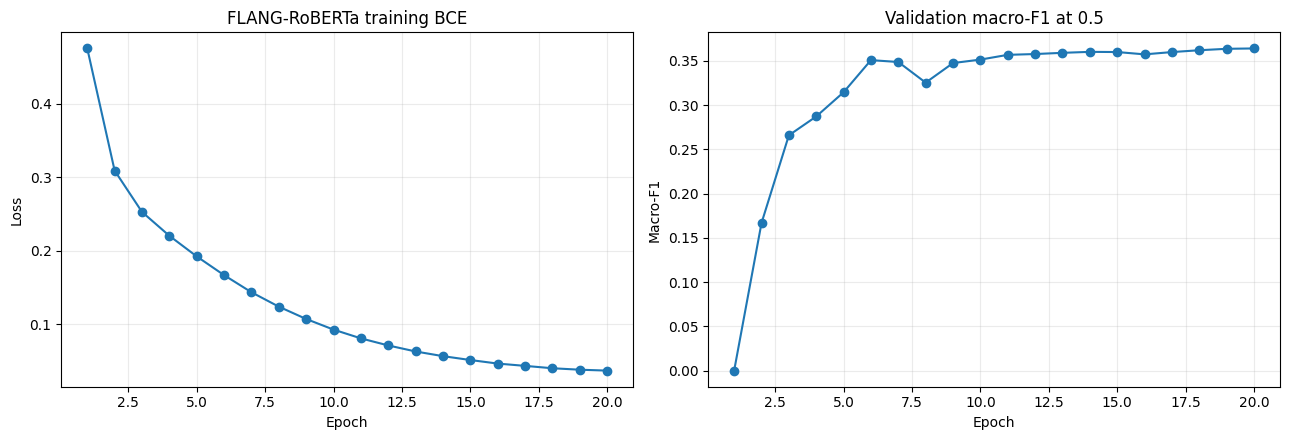

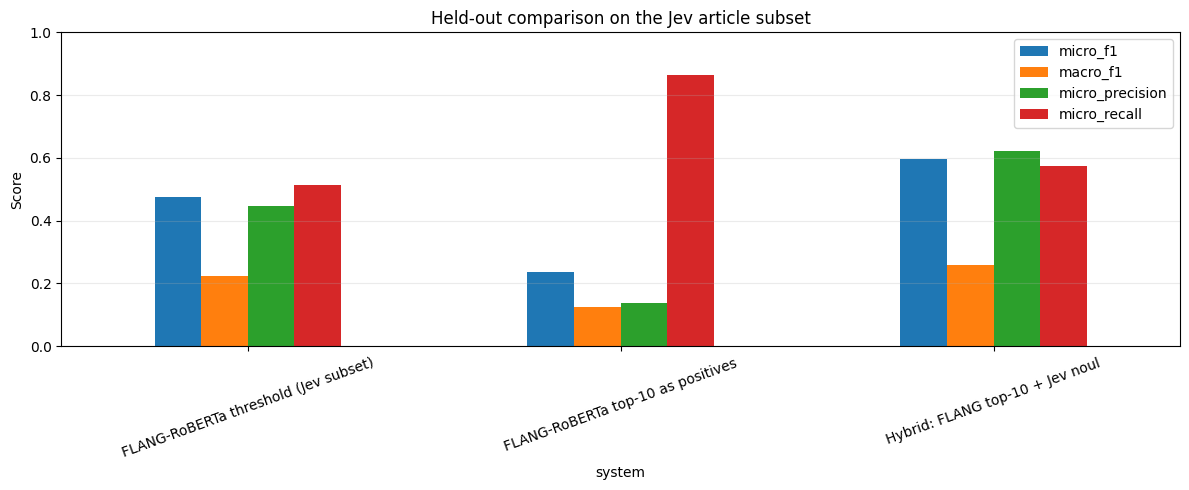

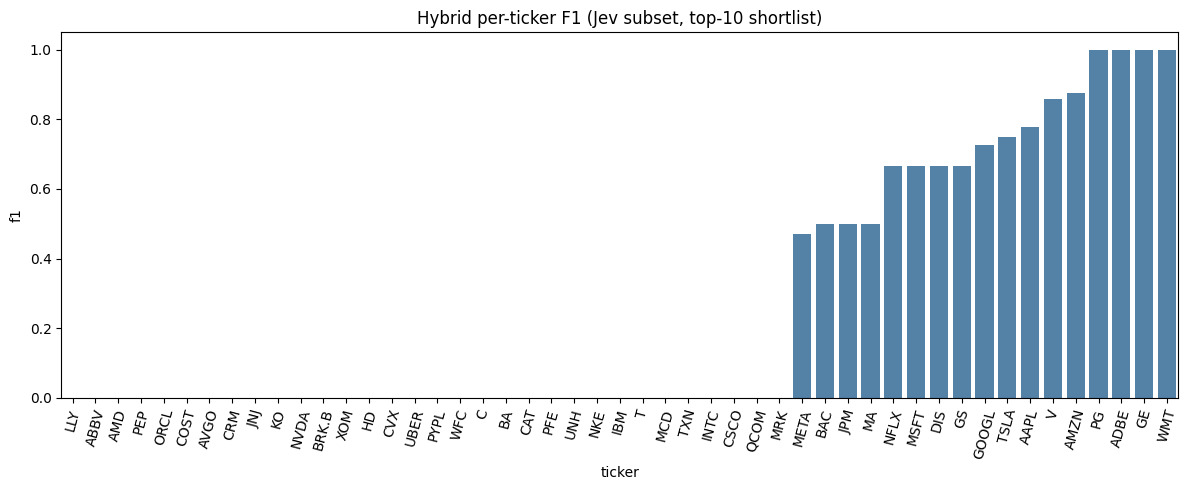

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
if len(history_df):
    axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o")
    axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], marker="o")
axes[0].set(title="FLANG-RoBERTa training BCE", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Validation macro-F1 at 0.5", xlabel="Epoch", ylabel="Macro-F1")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "flang_training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

plot_metrics = comparison.set_index("system")[["micro_f1", "macro_f1", "micro_precision", "micro_recall"]]
ax = plot_metrics.plot(kind="bar", figsize=(12, 5), rot=20)
ax.set(title="Held-out comparison on the Jev article subset", ylabel="Score", ylim=(0, 1))
ax.grid(axis="y", alpha=0.25)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hybrid_system_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(data=per_ticker.sort_values("f1"), x="ticker", y="f1", color="steelblue")
plt.xticks(rotation=75)
plt.title(f"Hybrid per-ticker F1 (Jev subset, top-{TOP_K} shortlist)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "hybrid_per_ticker_f1.png", dpi=160, bbox_inches="tight")
plt.show()


In [11]:
predicted_tickers = ["|".join(np.array(TICKERS)[row.astype(bool)]) for row in hybrid_pred_test]
shortlist_text = ["|".join(symbols) for symbols in test_shortlists]
test_predictions = pd.DataFrame({
    "_row_id": test_ids,
    "gold_tickers": ["|".join(xs) for xs in test_join["gold_tickers"]],
    "flang_shortlist": shortlist_text,
    "hybrid_predicted_tickers": predicted_tickers,
})
comparison.to_csv(OUTPUT_DIR / "hybrid_ticker_metrics.csv", index=False)
per_ticker.to_csv(OUTPUT_DIR / "hybrid_ticker_performance.csv", index=False)
pd.DataFrame([flang_metrics]).to_csv(OUTPUT_DIR / "flang_full_eval_metrics.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "flang_training_history.csv", index=False)
test_predictions.to_csv(OUTPUT_DIR / "hybrid_test_predictions.csv", index=False)
print("Saved outputs:", OUTPUT_DIR)
display(comparison)


Saved outputs: /kaggle/working/hybrid_flang_jev_ticker


,system,n,threshold,micro_f1,macro_f1,micro_precision,micro_recall,macro_precision,macro_recall,exact_match,hamming_loss,macro_average_precision,macro_ap_label_count,recall_at_k,exact_gold_in_top_k,jev_questions_per_article
0,FLANG-RoBERTa threshold (Jev subset),50,0.364611,0.476744,0.224899,0.445652,0.5125,0.218931,0.246113,0.32,0.036735,0.595654,23.0,0.8625,0.82,0
1,FLANG-RoBERTa top-10 as positives,50,NaN,0.237931,0.125710,0.138000,0.8625,0.087376,0.358844,0.00,0.180408,NaN,NaN,0.8625,0.82,0
2,Hybrid: FLANG top-10 + Jev noul,50,0.031293,0.597403,0.257642,0.621622,0.5750,0.263003,0.279397,0.26,0.025306,0.579692,23.0,0.8625,0.82,10


## Metrics and interpretation

- **FLANG-RoBERTa threshold** is the standalone classifier: one global cutoff chosen on validation macro-F1, then applied to all 49 tickers.
- **Top-k as positives** treats the retriever shortlist itself as the predicted set. Precision is usually weak because k is larger than typical gold cardinality.
- **Hybrid** asks Jev only about the shortlist. A gold ticker missing from top-k is an automatic false negative.
- **Recall@k** is the fraction of gold ticker occurrences recovered by the shortlist. Raise `TOP_K` if this is low; lower it to save Jev calls if it is already high.
- Jev responses are cached under `/kaggle/working/hybrid_flang_jev_ticker/cache/` so reruns skip completed articles.

The ticker arrays are source annotations from the benchmark CSV, not independently adjudicated gold labels.
